# Credit card approval prediction

Banks reject a large share of credit card applications, and reviewing each one by hand is slow. This notebook builds a small classifier that predicts whether an application is approved, using the [Credit Approval dataset](http://archive.ics.uci.edu/ml/datasets/credit+approval) from the UCI Machine Learning Repository (690 applications).

Steps:

1. Load the data and name the columns
2. Look at missing values and class balance
3. Build a preprocessing + logistic regression pipeline
4. Evaluate on a held-out test set
5. Tune the regularisation strength with a grid search

## 1. Load the data

The file has no header and the feature names were anonymised by the contributor. The names below are the commonly used guesses for what each column represents. Missing values are stored as `?`, so they are converted to `NaN` on load.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

columns = ["Gender", "Age", "Debt", "Married", "BankCustomer", "EducationLevel",
           "Ethnicity", "YearsEmployed", "PriorDefault", "Employed", "CreditScore",
           "DriversLicense", "Citizen", "ZipCode", "Income", "ApprovalStatus"]

cc_apps = pd.read_csv("datasets/cc_approvals.data", header=None, names=columns, na_values="?")
cc_apps.head()

,Gender,Age,Debt,Married,BankCustomer,EducationLevel,Ethnicity,YearsEmployed,PriorDefault,Employed,CreditScore,DriversLicense,Citizen,ZipCode,Income,ApprovalStatus
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,202.0,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,43.0,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,280.0,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,100.0,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,120.0,0,+


## 2. Inspect the data

In [2]:
cc_apps.info()

<class 'pandas.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          678 non-null    str    
 1   Age             678 non-null    float64
 2   Debt            690 non-null    float64
 3   Married         684 non-null    str    
 4   BankCustomer    684 non-null    str    
 5   EducationLevel  681 non-null    str    
 6   Ethnicity       681 non-null    str    
 7   YearsEmployed   690 non-null    float64
 8   PriorDefault    690 non-null    str    
 9   Employed        690 non-null    str    
 10  CreditScore     690 non-null    int64  
 11  DriversLicense  690 non-null    str    
 12  Citizen         690 non-null    str    
 13  ZipCode         677 non-null    float64
 14  Income          690 non-null    int64  
 15  ApprovalStatus  690 non-null    str    
dtypes: float64(4), int64(2), str(10)
memory usage: 93.8 KB


In [3]:
cc_apps.describe()

,Age,Debt,YearsEmployed,CreditScore,ZipCode,Income
count,678.000000,690.000000,690.000000,690.00000,677.000000,690.000000
mean,31.568171,4.758725,2.223406,2.40000,184.014771,1017.385507
std,11.957862,4.978163,3.346513,4.86294,173.806768,5210.102598
min,13.750000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,22.602500,1.000000,0.165000,0.00000,75.000000,0.000000
50%,28.460000,2.750000,1.000000,0.00000,160.000000,5.000000
75%,38.230000,7.207500,2.625000,3.00000,276.000000,395.500000
max,80.250000,28.000000,28.500000,67.00000,2000.000000,100000.000000


Missing values per column. Only 37 of the 690 rows have any gap, so imputing is safe.

In [4]:
missing = cc_apps.isna().sum()
print(missing[missing > 0])
print("\nRows with at least one missing value:", cc_apps.isna().any(axis=1).sum())

Gender            12
Age               12
Married            6
BankCustomer       6
EducationLevel     9
Ethnicity          9
ZipCode           13
dtype: int64

Rows with at least one missing value: 37


The target is fairly balanced, so accuracy is a reasonable headline metric. Always predicting "denied" would score about 55.5%, which is the baseline to beat.

In [5]:
cc_apps["ApprovalStatus"].value_counts(normalize=True).round(3)

ApprovalStatus
-    0.555
+    0.445
Name: proportion, dtype: float64

## 3. Features, target and train/test split

`DriversLicense` and `ZipCode` are dropped: neither has an obvious link to creditworthiness, and `ZipCode` has 170 distinct values for 690 rows.

The target is encoded as 1 = approved (`+`) and 0 = denied (`-`). It is separated from the features **before** any encoding, so no information about the label can leak into the model inputs.

In [6]:
from sklearn.model_selection import train_test_split

X = cc_apps.drop(columns=["DriversLicense", "ZipCode", "ApprovalStatus"])
y = (cc_apps["ApprovalStatus"] == "+").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(462, 13) (228, 13)


## 4. Preprocessing and model pipeline

- Numeric columns: fill gaps with the training median, then scale to 0-1.
- Categorical columns: fill gaps with the most frequent training value, then one-hot encode.

Putting these steps in a `Pipeline` means they are fitted on the training data only, including inside each cross-validation fold.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:    ", numeric_cols)
print("Categorical:", categorical_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", MinMaxScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

model = Pipeline([("preprocess", preprocess),
                  ("logreg", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

Numeric:     ['Age', 'Debt', 'YearsEmployed', 'CreditScore', 'Income']
Categorical: ['Gender', 'Married', 'BankCustomer', 'EducationLevel', 'Ethnicity', 'PriorDefault', 'Employed', 'Citizen']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Gender','Age','Debt',...,'CreditScore','Citizen','Income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining co

## 5. Evaluate on the test set

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score

y_pred = model.predict(X_test)
print(f"Test accuracy: {model.score(X_test, y_test):.3f}")
print(f"Test ROC AUC:  {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Denied", "Approved"]))

Test accuracy: 0.864
Test ROC AUC:  0.945

              precision    recall  f1-score   support

      Denied       0.88      0.87      0.88       127
    Approved       0.84      0.85      0.85       101

    accuracy                           0.86       228
   macro avg       0.86      0.86      0.86       228
weighted avg       0.86      0.86      0.86       228



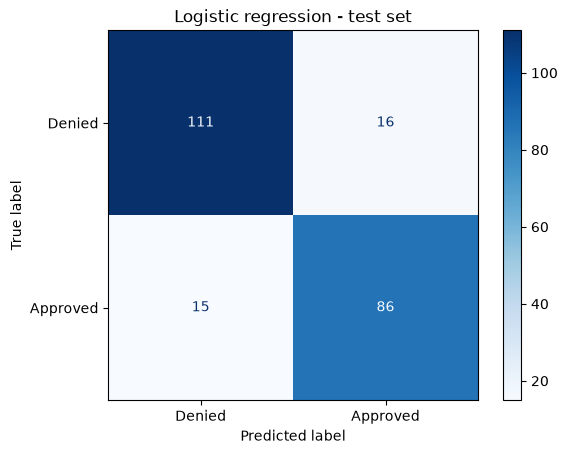

In [9]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Denied", "Approved"], cmap="Blues")
plt.title("Logistic regression - test set")
plt.show()

## 6. Tune the model

The grid search covers the regularisation strength `C` (smaller means stronger regularisation), scored with 5-fold cross-validation on the training set. The test set is only used once at the end.

In [10]:
from sklearn.model_selection import GridSearchCV

param_grid = {"logreg__C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(model, param_grid, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best cross-validated accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy of best model:   {grid.score(X_test, y_test):.3f}")

Best parameters: {'logreg__C': 0.01}
Best cross-validated accuracy: 0.857
Test accuracy of best model:   0.860


## 7. Which features matter?

Coefficients of the tuned model, largest in absolute size first. Positive values push towards approval.

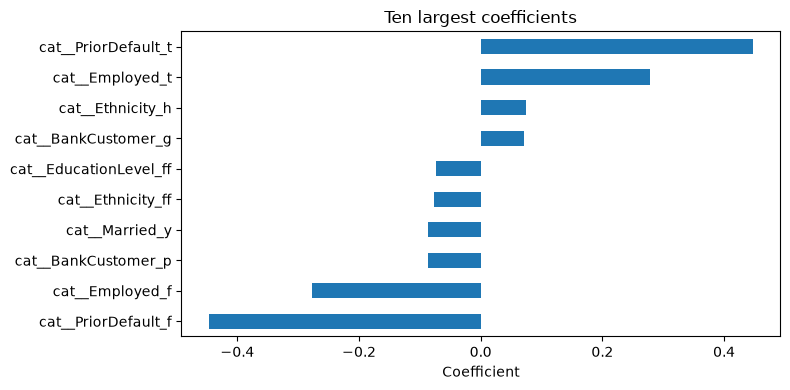

In [11]:
best = grid.best_estimator_
feature_names = best.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(best.named_steps["logreg"].coef_[0], index=feature_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

top.sort_values().plot.barh(figsize=(8, 4))
plt.xlabel("Coefficient")
plt.title("Ten largest coefficients")
plt.tight_layout()
plt.show()

## Summary

- A logistic regression on 13 features reaches about 86% accuracy and a ROC AUC of about 0.95 on unseen applications, against a 55.5% majority-class baseline.
- Tuning `C` does not change the picture much: cross-validated and test accuracy both stay around 86%, so the default model is already close to what this model family can do here.
- `PriorDefault` has by far the largest coefficient, followed by `Employed`. Every other feature contributes much less in the tuned, strongly regularised model.

Possible next steps: compare against a tree-based model, and check calibration of the predicted probabilities if they were to be used as scores.